# 06 - Audit the predictions of any classifier

callmefair cannot train every model in the world, and it does not need to. If you have a table with the *true
outcome*, the model's *prediction* and the *group columns*, `audit_predictions` / `audit_file` tell you whether the
predictions are biased, with the same metrics and fairness score used everywhere else in the library.

**What you'll learn**
1. how to audit a CSV produced by a model trained outside callmefair;
2. how to read the verdict, the metrics table and the per-group rates;
3. how to compare several models on one plot;
4. how to say who the privileged group is (value, list, callable, text) and audit intersections;
5. how to run the same audit from the command line;
6. what the numbers cannot tell you.

**Prerequisites:** notebooks 00 (data and groups) and 01 (fairness metrics).
**Runtime:** about 30 seconds on a laptop. **Data:** stroke prediction.

In [1]:
from fhg_examples import setup; setup()

In [2]:
import subprocess
import sys
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import train_test_split

from callmefair import audit_file, audit_predictions
from callmefair.viz import plot_fair_ranges, plot_group_rates
from fhg_examples.datasets import load

## 1. Scenario: a CSV from another team

Another team trained a model you cannot run inside callmefair, and sends you a CSV with the outcome, their
predictions and the group columns. We simulate it: a scikit-learn `HistGradientBoostingClassifier` (trained here,
outside callmefair) and a "vendor" rule that flags everyone aged 65+ or with a high glucose level. Positive means
"flagged for follow-up care", the favorable outcome.

The processed stroke data only has *binary* group columns (`age` 1 = 65+, `gender` 1 = Male, see notebook 00). We keep
them and add readable text columns, so the file looks like something a real team would send. Everything is written to a
temporary folder that is deleted at the end; nothing lands in the repository.

In [3]:
tmp = tempfile.TemporaryDirectory()
df = load("stroke")
train, test = train_test_split(df, test_size=0.3, random_state=0, stratify=df["stroke"])
features = [c for c in df.columns if c != "stroke"]

hgb = HistGradientBoostingClassifier(class_weight="balanced", random_state=0)
hgb.fit(train[features], train["stroke"])

sent = pd.DataFrame({
    "age": test["age"], "gender": test["gender"],
    "age_group": test["age"].map({1: "65+", 0: "<65"}),
    "sex": test["gender"].map({1: "Male", 0: "Female"}),
    "y_true": test["stroke"],
    "pred_hgb": hgb.predict(test[features]),
    "pred_rule": ((test["age"] == 1) | (test["avg_glucose_level"] > 150)).astype(int),
})
path = Path(tmp.name) / "predictions.csv"
sent.to_csv(path, index=False)
pd.read_csv(path).head()

,age,gender,age_group,sex,y_true,pred_hgb,pred_rule
0,0,1,<65,Male,0,0,0
1,0,0,<65,Female,0,0,0
2,0,1,<65,Male,0,0,0
3,0,0,<65,Female,0,0,0
4,0,1,<65,Male,0,0,0


## 2. Audit the file

Tell callmefair which column is the truth (`label`), which is the prediction, and for each protected attribute **which
value is the privileged group**. Everyone else is the unprivileged group. `favorable_label` is the outcome that is good
for the individual (here 1).

Printing the report gives a verdict per attribute: the metrics outside their acceptable range, and the composite
fairness score (0 = fair, higher = more biased).

In [4]:
report = audit_file(path, label="y_true", prediction="pred_hgb",
                    protected={"age": 1, "gender": 1}, model="HistGB")
print(report)

age: biased: EOD -0.30 outside (-0.1, 0.1), AOD -0.30 outside (-0.1, 0.1), SPD -0.31 outside (-0.1, 0.1), DI 0.09 outside (0.8, 1.2); fairness score 1.00 (0 = fair)
gender: biased: EOD -0.17 outside (-0.1, 0.1); fairness score 0.44 (0 = fair)


`to_frame()` has one row per attribute with every metric. Differences are *unprivileged minus privileged*, so a
negative SPD means the unprivileged group is flagged less often.

In [5]:
report.to_frame().T

,0,1
attribute,age,gender
model,HistGB,HistGB
balanced_acc,0.59,0.59
acc,0.881,0.881
precision,0.136,0.136
recall,0.267,0.267
f1,0.18,0.18
mcc,0.132,0.132
eq_opp_diff,-0.301,-0.173
avg_odd_diff,-0.303,-0.089


## 3. Where does the gap come from? The group table

The metrics are summaries of these per-group rates. `base_rate` is how often the true outcome happens, `selection_rate`
how often the model says "favorable", and TPR / FPR the error rates.

In [6]:
report.groups("age")

,group,n,base_rate,selection_rate,TPR,FPR,precision
0,privileged,320,0.150,0.341,0.375,0.335,0.165
1,unprivileged,1213,0.022,0.031,0.074,0.030,0.053


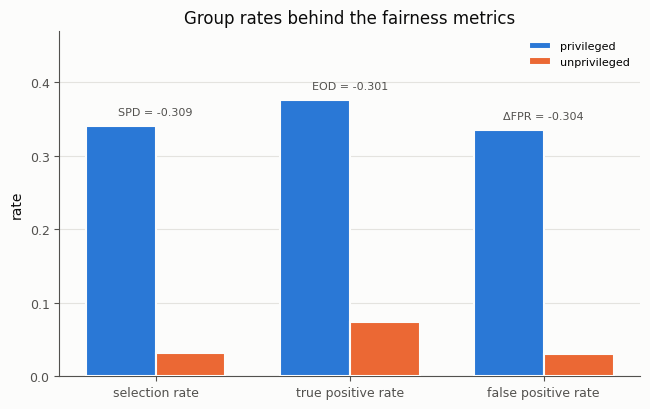

In [7]:
_ = plot_group_rates(report, attribute="age")
plt.show()

## 4. Compare several models

Pass a list of prediction columns to audit them all at once (model names are the column names).
`report.to_rows()` returns rows in the same format as the grid search, so every plot in `callmefair.viz` works on them.
Dots inside the shaded band are within the acceptable range.

In [8]:
both = audit_file(path, label="y_true", prediction=["pred_hgb", "pred_rule"],
                  protected={"age": 1, "gender": 1})
print(both)

[pred_hgb] age: biased: EOD -0.30 outside (-0.1, 0.1), AOD -0.30 outside (-0.1, 0.1), SPD -0.31 outside (-0.1, 0.1), DI 0.09 outside (0.8, 1.2); fairness score 1.00 (0 = fair)
[pred_rule] age: biased: EOD -0.67 outside (-0.1, 0.1), AOD -0.78 outside (-0.1, 0.1), SPD -0.90 outside (-0.1, 0.1), DI 0.10 outside (0.8, 1.2); fairness score 1.00 (0 = fair)
[pred_hgb] gender: biased: EOD -0.17 outside (-0.1, 0.1); fairness score 0.44 (0 = fair)
[pred_rule] gender: fair: all 5 metrics within range; fairness score 0.12 (0 = fair)


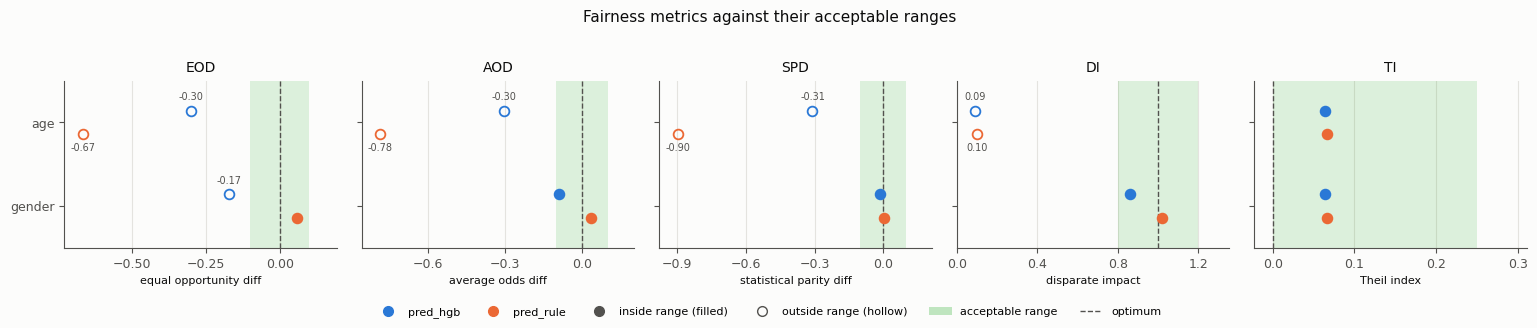

In [9]:
_ = plot_fair_ranges(both.to_rows())
plt.show()

## 5. Saying who is privileged

The privileged group can be given as a value, a list of values, or a function of the column, so non-binary and text
columns work as they are. These four calls describe the same group and give the same result:

In [10]:
specs = {"value": {"age": 1}, "list": {"age": [1]}, "text": {"age_group": "65+"},
         "callable": {"age": lambda s: s >= 1}}
pd.Series({name: next(iter(audit_predictions(sent, label="y_true", prediction="pred_hgb", protected=spec)
                          .to_frame().spd)) for name, spec in specs.items()}, name="SPD")

value      -0.309
list       -0.309
text       -0.309
callable   -0.309
Name: SPD, dtype: float64

`intersections=True` also audits every pair of attributes; the privileged group of a pair is privileged in *both*
(here: older **and** male).

In [11]:
inter = audit_predictions(sent, label="y_true", prediction="pred_hgb", intersections=True,
                          protected={"age_group": "65+", "sex": "Male"}, model="HistGB")
print(inter)
inter.groups("age_group_sex")

age_group: biased: EOD -0.30 outside (-0.1, 0.1), AOD -0.30 outside (-0.1, 0.1), SPD -0.31 outside (-0.1, 0.1), DI 0.09 outside (0.8, 1.2); fairness score 1.00 (0 = fair)
sex: biased: EOD -0.17 outside (-0.1, 0.1); fairness score 0.44 (0 = fair)
age_group_sex: biased: EOD -0.33 outside (-0.1, 0.1), AOD -0.30 outside (-0.1, 0.1), SPD -0.30 outside (-0.1, 0.1), DI 0.20 outside (0.8, 1.2); fairness score 1.00 (0 = fair)


,group,n,base_rate,selection_rate,TPR,FPR,precision
0,privileged,116,0.190,0.371,0.50,0.34,0.256
1,unprivileged,1417,0.037,0.073,0.17,0.07,0.087


## 6. The same from the command line

No Python needed: this is what you would run on the file you received (here via `subprocess`).
Several `--protected` options can be given; use `ATTR=A,B` for several privileged values.

In [12]:
cmd = [sys.executable, "-m", "callmefair.audit", str(path), "--label", "y_true",
       "--prediction", "pred_hgb", "pred_rule", "--protected", "age=1", "--protected", "sex=Male"]
print("$ python -m callmefair.audit predictions.csv --label y_true --prediction pred_hgb pred_rule "
      "--protected age=1 --protected sex=Male\n")
print(subprocess.run(cmd, capture_output=True, text=True).stdout)

$ python -m callmefair.audit predictions.csv --label y_true --prediction pred_hgb pred_rule --protected age=1 --protected sex=Male



[pred_hgb] age: biased: EOD -0.30 outside (-0.1, 0.1), AOD -0.30 outside (-0.1, 0.1), SPD -0.31 outside (-0.1, 0.1), DI 0.09 outside (0.8, 1.2); fairness score 1.00 (0 = fair)
[pred_rule] age: biased: EOD -0.67 outside (-0.1, 0.1), AOD -0.78 outside (-0.1, 0.1), SPD -0.90 outside (-0.1, 0.1), DI 0.10 outside (0.8, 1.2); fairness score 1.00 (0 = fair)
[pred_hgb] sex: biased: EOD -0.17 outside (-0.1, 0.1); fairness score 0.44 (0 = fair)
[pred_rule] sex: fair: all 5 metrics within range; fairness score 0.12 (0 = fair)

attribute     model  balanced_acc   acc  precision  recall   f1   mcc  eq_opp_diff  avg_odd_diff    spd  disparate_impact  theil_idx  fair_score  fair_score_uncapped  is_fair
      age  pred_hgb         0.590 0.881      0.136   0.267 0.18 0.132       -0.301        -0.303 -0.309             0.092      0.064       1.000                1.682    False
      age pred_rule         0.747 0.736      0.128   0.760 0.22 0.235       -0.667        -0.785 -0.898             0.102      0

In [13]:
tmp.cleanup()  # the temporary folder and the CSV are gone

## 7. How to read the result

- **Base-rate gap vs error gap.** If the older group really has more strokes, a model that flags them more often is
  not necessarily unfair: compare `base_rate` with `selection_rate`, and look at TPR / FPR. A gap in TPR (EOD) means
  equally sick people are treated differently, which is harder to justify than a gap in selection rate (SPD).
- **Small groups.** Metrics from a handful of positives are noisy; check the `n` column. A group without any true
  positive makes TPR-based metrics undefined (callmefair warns and the score treats them as unfair).
- **The audit sees outcomes, not causes.** It says *that* predictions differ across groups, not *why*, and only for the
  groups you specify.
- **Fixing it.** If you can retrain the model, use the mitigation grid of notebook 03. If you only have hard labels,
  post-processing there needs the model's scores, so ask the other team for probabilities.

## Summary

- `audit_file` / `audit_predictions` need only the true label, the prediction and the group columns.
- The report gives a verdict, the five fairness metrics, the composite score and a per-group table.
- `to_rows()` plugs the result into `callmefair.viz`; several prediction columns compare models.
- Privileged groups can be a value, list, callable or text; `intersections=True` audits pairs.
- `python -m callmefair.audit` does the same from a shell.

**Next:** [03_bias_mitigation.ipynb](03_bias_mitigation.ipynb) to reduce the bias of a model you can retrain, or
[04_tradeoff_map.ipynb](04_tradeoff_map.ipynb) to judge whether a mitigation beats simply degrading the model.